In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

In [4]:
df=pd.read_csv('/content/marketing_campaign.csv', sep='\t')

In [5]:
df.shape

(2240, 29)

In [6]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   i

In [8]:
df['Income']=df['Income'].fillna(df['Income'].median())

current_year=2026
df['Age']=current_year-df['Year_Birth']

spending_cols=['MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']
df['Total_Income']=df[spending_cols].sum(axis=1)

df['Children']=df['Kidhome']+df['Teenhome']

features=['Income', 'Age', 'Total_Income', 'Children', 'Recency', 'NumWebVisitsMonth']

X=df[features].copy()

X = X[(X['Age']<100) & (X['Income']<200000)]  #Removing extreme outliers

X.head()

,Income,Age,Total_Income,Children,Recency,NumWebVisitsMonth
0,58138.0,69,1617,0,58,7
1,46344.0,72,27,2,38,5
2,71613.0,61,776,0,26,4
3,26646.0,42,53,1,26,6
4,58293.0,45,422,1,94,5


In [9]:
scaler=StandardScaler()
X=scaler.fit_transform(X)

**K-Means Clustering**

Elbow Method

Text(0.5, 1.0, 'Elbow Method for Optimal K Selection')

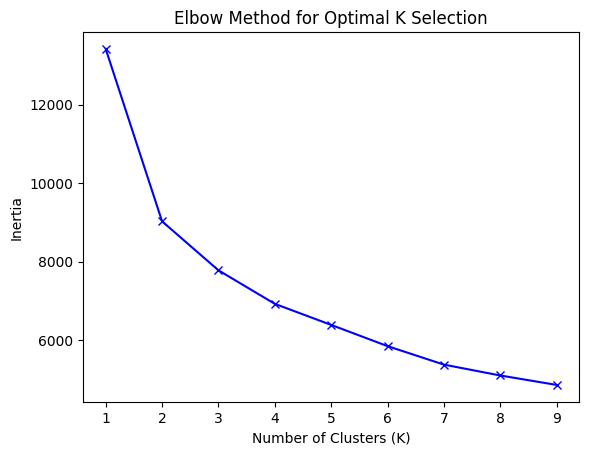

In [10]:
inertia=[]
K_range=range(1, 10)
for k in K_range:
  kmeans=KMeans(n_clusters=k, random_state=42)
  kmeans.fit(X)
  inertia.append(kmeans.inertia_)
plt.plot(K_range, inertia, 'bx-')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal K Selection')

Silhouette Method

For K = 2, Silhouette Score = 0.2978
For K = 3, Silhouette Score = 0.2148
For K = 4, Silhouette Score = 0.2114
For K = 5, Silhouette Score = 0.2062
For K = 6, Silhouette Score = 0.1931
For K = 7, Silhouette Score = 0.2006
For K = 8, Silhouette Score = 0.2016
For K = 9, Silhouette Score = 0.1980


Text(0.5, 1.0, 'Silhouette Method for Optimal K Selection')

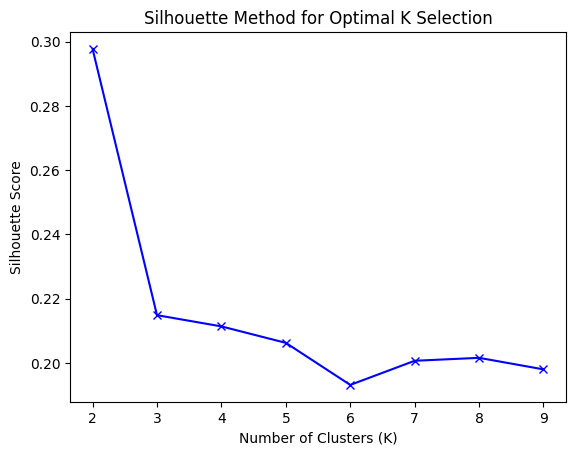

In [11]:
from sklearn.metrics import silhouette_score

silhouette_scores=[]
k_range=range(2,10)
for k in k_range:
  kmeans=KMeans(n_clusters=k, random_state=42)
  labels=kmeans.fit_predict(X)
  score=silhouette_score(X, labels)
  silhouette_scores.append(score)
  print(f"For K = {k}, Silhouette Score = {score:.4f}")

plt.plot(k_range, silhouette_scores, 'bx-')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Method for Optimal K Selection')

K-Means Cluster Counts:
KMeans_Cluster
2    862
1    695
0    679
Name: count, dtype: int64


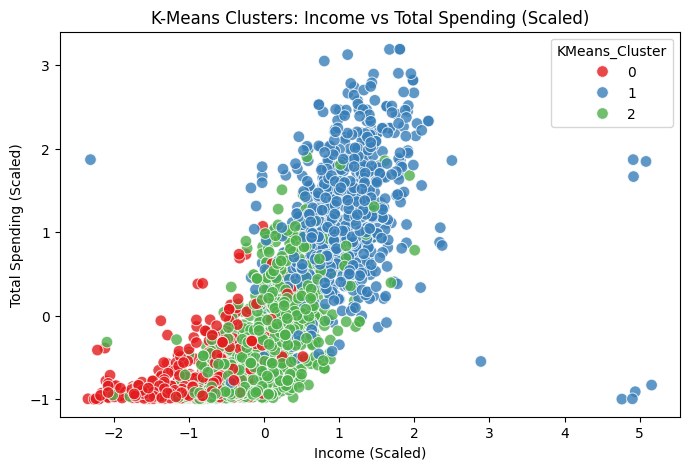

In [13]:
import seaborn as sns
import pandas as pd

X_df = pd.DataFrame(X, columns=['Income', 'Age', 'Total_Income', 'Children', 'Recency', 'NumWebVisitsMonth'])

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
X_df['KMeans_Cluster'] = kmeans.fit_predict(X_df)

print("K-Means Cluster Counts:")
print(X_df['KMeans_Cluster'].value_counts())

plt.figure(figsize=(8, 5))
sns.scatterplot(
    x='Income',
    y='Total_Income',
    hue='KMeans_Cluster',
    data=X_df,
    palette='Set1',
    s=70,
    alpha=0.8
)
plt.title('K-Means Clusters: Income vs Total Spending (Scaled)')
plt.xlabel('Income (Scaled)')
plt.ylabel('Total Spending (Scaled)')
plt.show()

**DBSCAN**

DBSCAN Cluster Counts (-1 represents noise/outliers):
DBSCAN_Cluster
 2    1117
 0     617
 1     412
-1      49
 3      34
 4       7
Name: count, dtype: int64


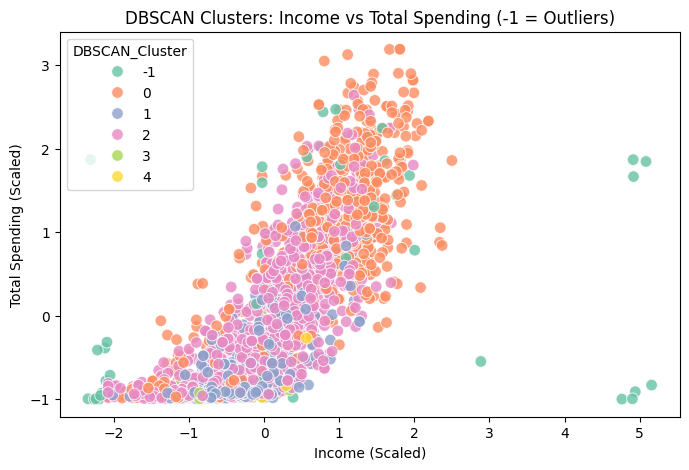

In [16]:
dbscan = DBSCAN(eps=1.2, min_samples=5)
X_df['DBSCAN_Cluster'] = dbscan.fit_predict(X)

print("DBSCAN Cluster Counts (-1 represents noise/outliers):")
print(X_df['DBSCAN_Cluster'].value_counts())

plt.figure(figsize=(8, 5))
sns.scatterplot(
    x='Income',
    y='Total_Income',
    hue='DBSCAN_Cluster',
    data=X_df,
    palette='Set2',
    s=70,
    alpha=0.8
)
plt.title('DBSCAN Clusters: Income vs Total Spending (-1 = Outliers)')
plt.xlabel('Income (Scaled)')
plt.ylabel('Total Spending (Scaled)')
plt.show()

PCA & t-SNE

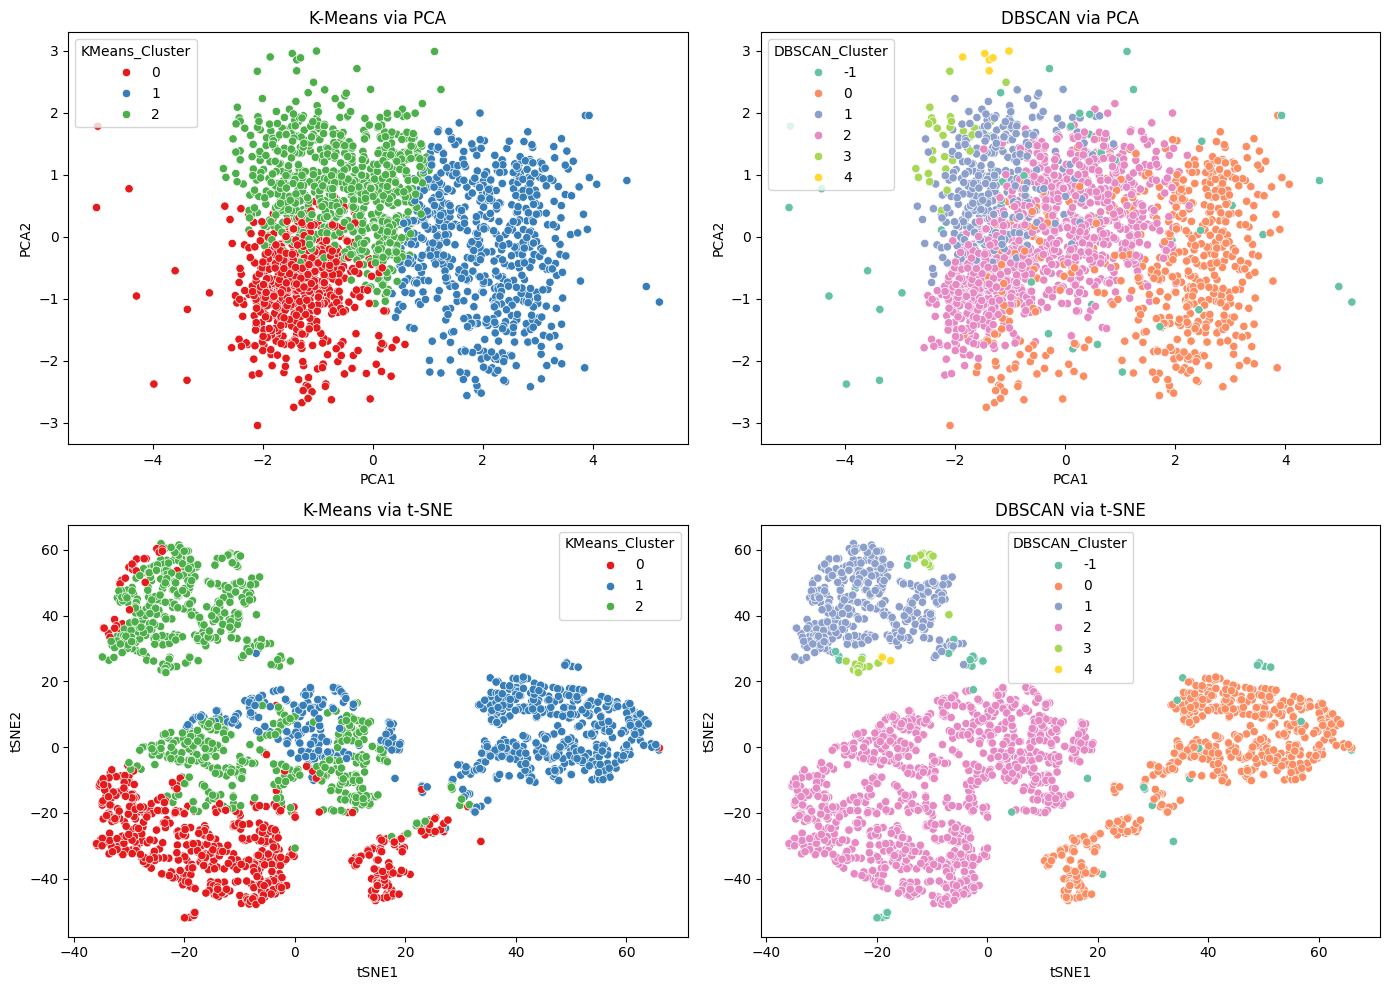

In [19]:
pca = PCA(n_components=2)
pca_res = pca.fit_transform(X)

X_df['PCA1'], X_df['PCA2'] = pca_res[:, 0], pca_res[:, 1]

tsne = TSNE(n_components=2, perplexity=30, random_state=42)
tsne_res = tsne.fit_transform(X)

X_df['tSNE1'], X_df['tSNE2'] = tsne_res[:, 0], tsne_res[:, 1]


fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.scatterplot(x='PCA1', y='PCA2', hue='KMeans_Cluster', data=X_df, palette='Set1', ax=axes[0, 0])
axes[0, 0].set_title('K-Means via PCA')

sns.scatterplot(x='PCA1', y='PCA2', hue='DBSCAN_Cluster', data=X_df, palette='Set2', ax=axes[0, 1])
axes[0, 1].set_title('DBSCAN via PCA')

sns.scatterplot(x='tSNE1', y='tSNE2', hue='KMeans_Cluster', data=X_df, palette='Set1', ax=axes[1, 0])
axes[1, 0].set_title('K-Means via t-SNE')

sns.scatterplot(x='tSNE1', y='tSNE2', hue='DBSCAN_Cluster', data=X_df, palette='Set2', ax=axes[1, 1])
axes[1, 1].set_title('DBSCAN via t-SNE')

plt.tight_layout()
plt.show()